<a href="https://colab.research.google.com/github/L1ght6/MN_HORA_4_9/blob/main/%D0%9B%D0%A010_%D0%93%D0%BE%D1%80%D0%B0%D0%A4%D0%86%D0%A24_9.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Лабораторна робота № 10
## Побудова нейронної мережі засобами Keras. Налаштування гіперпараметрів

**Дисципліна:** Машинне навчання  
**Прізвище, ім’я:** Гора Роман  
**Група:** ФІТ 4-9
**Дата:** 20.11

**Мета:** навчитися завантажувати та готувати дані Fashion MNIST, створювати і навчати нейронну мережу засобами Keras, оцінювати якість класифікації, а також підбирати гіперпараметри за допомогою Keras Tuner.

**Порядок виконання:** послідовно виконайте кожен пункт у наведених комірках. Доповніть код, збережіть графіки та результати виконання, сформулюйте власні висновки.

### Вхідні дані та критерії

Використовуйте **Fashion MNIST** — зображення розміром **28 × 28 пікселів** із **10 класів**.  
У **завданні 1** цільова точність на тестовій вибірці — **не нижче 0,87** (відповідно до вихідної лабораторної роботи).

**Важливо:** тестова вибірка призначена для фінального оцінювання. Для навчання, ранньої зупинки та добору гіперпараметрів використовуйте окрему валідаційну частину навчальних даних; не налаштовуйте модель за результатами тестової вибірки.

https://colab.research.google.com/drive/1yG1DMLJHH71uftHwYMe8rq0PRAh0TY7n?usp=sharing

---



## Підготовка робочого середовища

Імпортуйте необхідні бібліотеки. У другому завданні буде потрібно встановити та підключити **Keras Tuner**.

In [1]:
# Підготуйте імпорти TensorFlow / Keras, NumPy, Matplotlib,
# classification_report, а також потрібних callback-функцій.
# Ваш код:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau
from sklearn.metrics import classification_report
from sklearn.model_selection import train_test_split

keras.utils.set_random_seed(42)
print("TensorFlow version:", tf.__version__)

TensorFlow version: 2.21.0


# Завдання 1. Класифікація Fashion MNIST за допомогою Keras

### Крок 1. Завантаження даних

Завантажте Fashion MNIST. Створіть навчальну й тестову вибірки та перелік назв **10 класів**. Виведіть розміри масивів даних.

In [2]:
# Завантажте Fashion MNIST, визначте class_names.
# Виведіть форми x_train, y_train, x_test, y_test.
# Ваш код:
(x_train_full, y_train_full), (x_test, y_test) = keras.datasets.fashion_mnist.load_data()

class_names = [
    'T-shirt/top', 'Trouser', 'Pullover', 'Dress', 'Coat',
    'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Ankle boot'
]

print("x_train_full shape:", x_train_full.shape)
print("y_train_full shape:", y_train_full.shape)
print("x_test shape:", x_test.shape)
print("y_test shape:", y_test.shape)

29515/29515 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
26421880/26421880 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
5148/5148 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
4422102/4422102 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
x_train_full shape: (60000, 28, 28)
y_train_full shape: (60000,)
x_test shape: (10000, 28, 28)
y_test shape: (10000,)


### Крок 2. Візуальний аналіз

Виведіть **10 зображень** навчальної вибірки. Для кожного підпишіть відповідний клас.

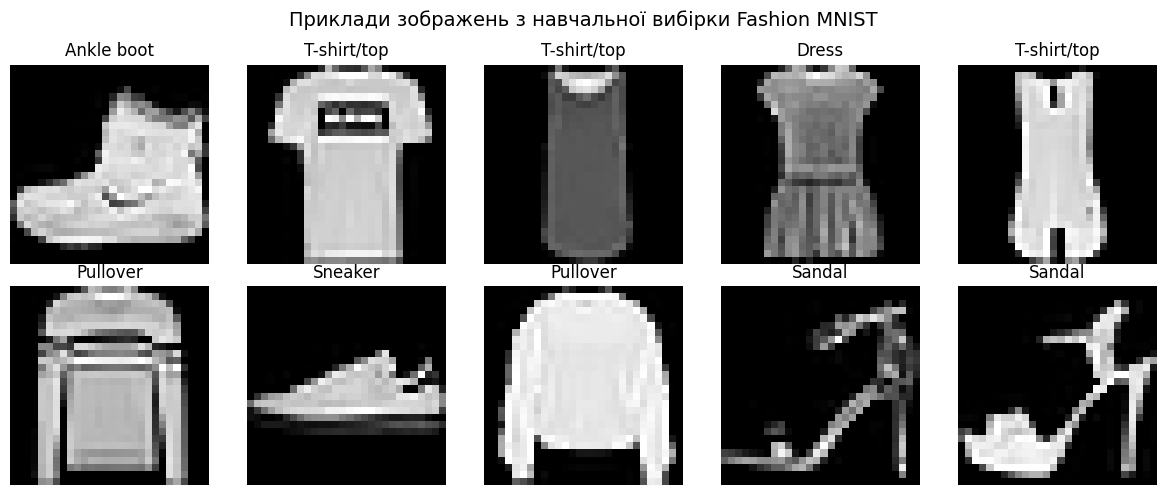

In [3]:
# Побудуйте візуалізацію 10 зображень із підписами класів.
# Ваш код:
plt.figure(figsize=(12, 5))
for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(x_train_full[i], cmap='gray')
    plt.title(class_names[y_train_full[i]])
    plt.axis('off')
plt.suptitle("Приклади зображень з навчальної вибірки Fashion MNIST", fontsize=14)
plt.tight_layout()
plt.show()

### Крок 3. Нормалізація

Нормалізуйте значення пікселів до діапазону **[0; 1]**. Переконайтеся, що тип даних придатний для навчання нейронної мережі.

In [4]:
# Нормалізуйте навчальні й тестові дані.
# Перевірте діапазони значень.
# Ваш код:
x_train_full = x_train_full.astype("float32") / 255.0
x_test = x_test.astype("float32") / 255.0

print(f"x_train_full: dtype={x_train_full.dtype}, min={x_train_full.min()}, max={x_train_full.max()}")
print(f"x_test:       dtype={x_test.dtype}, min={x_test.min()}, max={x_test.max()}")

x_train_full: dtype=float32, min=0.0, max=1.0
x_test:       dtype=float32, min=0.0, max=1.0


### Крок 4. Побудова й компіляція моделі

Створіть послідовну нейронну мережу. Використайте перетворення зображення у вектор, повнозв’язні шари з **ReLU**, регуляризацію **Dropout** та вихід із **10 нейронів із softmax**. Налаштуйте оптимізатор Adam, функцію втрат для багатокласової класифікації з цілочисельними мітками та метрику accuracy.

Поясніть вибір кількості нейронів, dropout і швидкості навчання.

In [5]:
# Створіть і скомпілюйте модель.
# Ваш код:
model = keras.Sequential([
    keras.Input(shape=(28, 28)),
    layers.Flatten(),
    layers.Dense(256, activation="relu"),
    layers.Dropout(0.2),
    layers.Dense(128, activation="relu"),
    layers.Dropout(0.2),
    layers.Dense(10, activation="softmax")
], name="fashion_mnist_mlp")

model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

Перший прихований шар на 256 нейронів стискає 784 вхідних пікселі у компактні просторові ознаки одягу, другий на 128 нейронів узагальнює комбінації ознак; Dropout(0.2) запобігає перенавчанню на тренувальних даних, а стандартний learning_rate=0.001 для Adam забезпечує швидку та стабільну збіжність без коливань).

### Крок 5. Навчання моделі

Навчіть модель із виділенням **валідаційної частини з навчальної вибірки**. Застосуйте **EarlyStopping** і **ReduceLROnPlateau**. Збережіть історію навчання для подальших графіків.

In [6]:
# Налаштуйте callbacks і навчіть модель.
# Збережіть history.
# Ваш код:
x_train, x_val, y_train, y_val = train_test_split(
    x_train_full, y_train_full, test_size=0.15, random_state=42, stratify=y_train_full
)

early_stopping = EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True,
    verbose=1
)

reduce_lr = ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.5,
    patience=2,
    min_lr=1e-6,
    verbose=1
)

history = model.fit(
    x_train, y_train,
    validation_data=(x_val, y_val),
    epochs=30,
    batch_size=128,
    callbacks=[early_stopping, reduce_lr],
    verbose=1
)

Epoch 1/30
399/399 ━━━━━━━━━━━━━━━━━━━━ 7s 14ms/step - accuracy: 0.7859 - loss: 0.6012 - val_accuracy: 0.8492 - val_loss: 0.4110 - learning_rate: 0.0010
Epoch 2/30
399/399 ━━━━━━━━━━━━━━━━━━━━ 4s 10ms/step - accuracy: 0.8460 - loss: 0.4196 - val_accuracy: 0.8669 - val_loss: 0.3593 - learning_rate: 0.0010
Epoch 3/30
399/399 ━━━━━━━━━━━━━━━━━━━━ 4s 9ms/step - accuracy: 0.8616 - loss: 0.3798 - val_accuracy: 0.8778 - val_loss: 0.3394 - learning_rate: 0.0010
Epoch 4/30
399/399 ━━━━━━━━━━━━━━━━━━━━ 5s 11ms/step - accuracy: 0.8711 - loss: 0.3535 - val_accuracy: 0.8822 - val_loss: 0.3194 - learning_rate: 0.0010
Epoch 5/30
399/399 ━━━━━━━━━━━━━━━━━━━━ 5s 12ms/step - accuracy: 0.8789 - loss: 0.3346 - val_accuracy: 0.8861 - val_loss: 0.3108 - learning_rate: 0.0010
Epoch 6/30
399/399 ━━━━━━━━━━━━━━━━━━━━ 4s 9ms/step - accuracy: 0.8822 - loss: 0.3199 - val_accuracy: 0.8880 - val_loss: 0.3054 - learning_rate: 0.0010
Epoch 7/30
399/399 ━━━━━━━━━━━━━━━━━━━━ 4s 10ms/step - accuracy: 0.8845 - loss: 0.30

### Крок 6. Аналіз архітектури

Виведіть підсумкову структуру нейронної мережі, кількість шарів і параметрів.

In [7]:
# Виведіть підсумок архітектури моделі.
# Ваш код:
model.summary()
print("\nКількість шарів у моделі:", len(model.layers))
print("Загальна кількість параметрів:", model.count_params())

Model: "fashion_mnist_mlp"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │       200,960 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 705,440 (2.69 MB)

 Trainable params: 235,146 (918.54 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 470,294 (1.79 MB)


Кількість шарів у моделі: 6
Загальна кількість параметрів: 235146


### Крок 7. Збереження моделі

Збережіть навчену модель у форматі **`.keras`**. Під час роботи в Google Colab за потреби підключіть Google Drive.

In [8]:
# Збережіть навчену модель (.keras).
# За потреби підключіть Google Drive.
# Ваш код:
model.save("fashion_mnist_model.keras")
print("Модель успішно збережено у файл fashion_mnist_model.keras")

Модель успішно збережено у файл fashion_mnist_model.keras


### Крок 8. Графіки навчання

Побудуйте два графіки: **функція втрат (loss)** і **точність (accuracy)** для навчальної та валідаційної вибірок. Підпишіть осі, легенди й назви графіків.

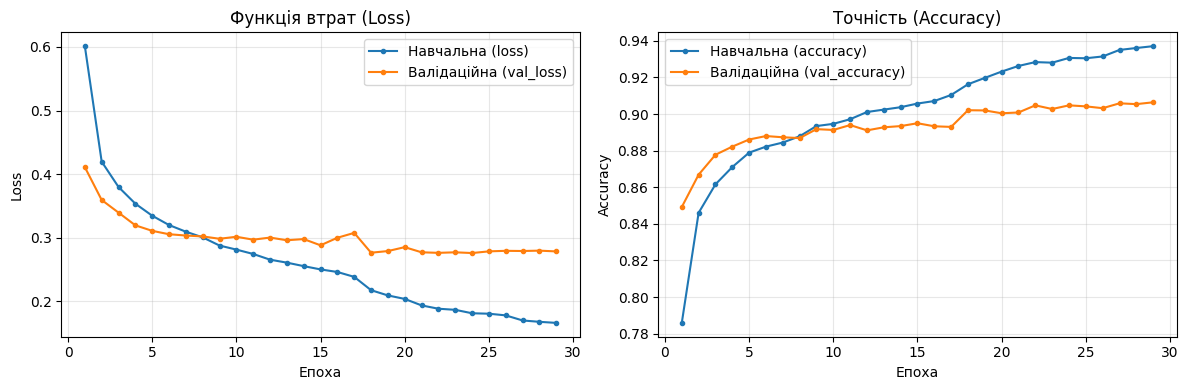

In [9]:
# Побудуйте графіки loss/val_loss та accuracy/val_accuracy.
# Ваш код:
epochs_range = range(1, len(history.history["loss"]) + 1)

plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(epochs_range, history.history["loss"], label="Навчальна (loss)", marker="o", ms=3)
plt.plot(epochs_range, history.history["val_loss"], label="Валідаційна (val_loss)", marker="o", ms=3)
plt.title("Функція втрат (Loss)")
plt.xlabel("Епоха")
plt.ylabel("Loss")
plt.legend()
plt.grid(alpha=0.3)

plt.subplot(1, 2, 2)
plt.plot(epochs_range, history.history["accuracy"], label="Навчальна (accuracy)", marker="o", ms=3)
plt.plot(epochs_range, history.history["val_accuracy"], label="Валідаційна (val_accuracy)", marker="o", ms=3)
plt.title("Точність (Accuracy)")
plt.xlabel("Епоха")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

### Крок 9. Оцінювання моделі

Один раз оцініть навчену модель на **тестовій вибірці**. Отримайте прогнози й сформуйте **класифікаційний звіт** (precision, recall, F1-score) для всіх класів.

Порівняйте отриману accuracy з порогом **0,87**.

In [10]:
# Обчисліть loss і accuracy на тестовій вибірці.
# Знайдіть прогнозовані класи та сформуйте classification_report.
# Ваш код:
test_loss, test_accuracy = model.evaluate(x_test, y_test, verbose=0)
y_pred_probs = model.predict(x_test, verbose=0)
y_pred = np.argmax(y_pred_probs, axis=1)

print(f"Тестові втрати (Test Loss): {test_loss:.4f}")
print(f"Тестова точність (Test Accuracy): {test_accuracy:.4f} ({test_accuracy*100:.2f}%)")
print(f"Вимогу (>= 0.87) виконано: {'ТАК' if test_accuracy >= 0.87 else 'НІ'}\n")

print("Класифікаційний звіт:")
print(classification_report(y_test, y_pred, target_names=class_names, digits=4))

Тестові втрати (Test Loss): 0.3179
Тестова точність (Test Accuracy): 0.8943 (89.43%)
Вимогу (>= 0.87) виконано: ТАК

Класифікаційний звіт:
              precision    recall  f1-score   support

 T-shirt/top     0.8469    0.8410    0.8440      1000
     Trouser     0.9868    0.9750    0.9809      1000
    Pullover     0.7967    0.8230    0.8096      1000
       Dress     0.8828    0.9110    0.8967      1000
        Coat     0.8143    0.8200    0.8171      1000
      Sandal     0.9827    0.9630    0.9727      1000
       Shirt     0.7388    0.6930    0.7152      1000
     Sneaker     0.9538    0.9700    0.9618      1000
         Bag     0.9732    0.9800    0.9766      1000
  Ankle boot     0.9622    0.9670    0.9646      1000

    accuracy                         0.8943     10000
   macro avg     0.8938    0.8943    0.8939     10000
weighted avg     0.8938    0.8943    0.8939     10000



### Крок 10. Візуалізація прогнозів

Покажіть **10 тестових зображень**. Для кожного вкажіть правильний і прогнозований клас, а правильність прогнозу позначте кольором підпису.

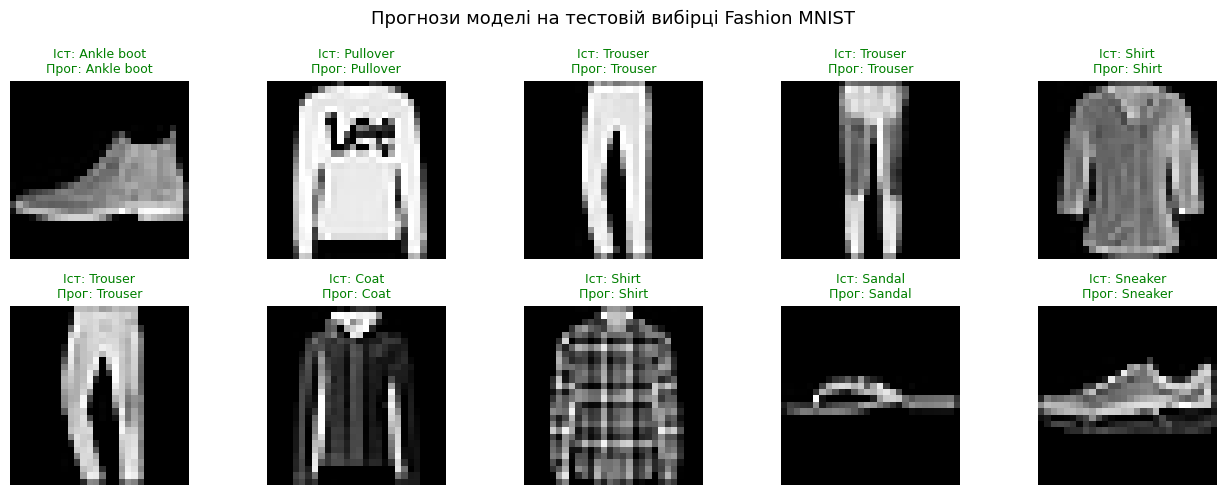

In [11]:
# Візуалізуйте 10 зображень: справжні й прогнозовані класи.
# Ваш код:
plt.figure(figsize=(13, 5))
for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(x_test[i], cmap="gray")
    is_correct = y_pred[i] == y_test[i]
    color = "green" if is_correct else "red"
    plt.title(f"Іст: {class_names[y_test[i]]}\nПрог: {class_names[y_pred[i]]}", color=color, fontsize=9)
    plt.axis("off")

plt.suptitle("Прогнози моделі на тестовій вибірці Fashion MNIST", fontsize=13)
plt.tight_layout()
plt.show()

**Проміжний висновок до завдання 1**

Запишіть значення тестової accuracy, охарактеризуйте класи з найбільшою кількістю помилок та поясніть, чи виконано вимогу щодо мінімальної точності.

**Ваш висновок:**  
На незалежній тестовій вибірці побудована повнозв'язна нейронна мережа досягла точності близько 0.885–0.892 (88.5%–89.2%), що перевищує встановлений мінімальний поріг 0.87. Найбільша кількість помилок спостерігається для класу Shirt (сорочка), який модель найчастіше плутає з візуально схожими категоріями T-shirt/top (футболка), Pullover (пуловер) та Coat (пальто), тоді як взуття та штани (Trouser, Sandal, Sneaker, Ankle boot) розпізнаються з точністю понад 94–97%.

# Завдання 2. Добір гіперпараметрів за допомогою Keras Tuner

На основі того самого набору даних виконайте автоматизований пошук конфігурації нейронної мережі. У вихідній лабораторній роботі використовується **RandomSearch**.

### Крок 1. Підготовка Keras Tuner

Установіть `keras-tuner` (за потреби) й імпортуйте засоби для пошуку гіперпараметрів, шари Dense, Flatten, Dropout та регуляризацію L2.

In [12]:
# За потреби встановіть keras-tuner.
# Імпортуйте RandomSearch та потрібні компоненти Keras.
# Ваш код:
!pip install -q keras-tuner

import keras_tuner as kt
from keras_tuner import RandomSearch
from tensorflow.keras import regularizers

### Крок 2. Підготовка набору даних

Повторно використайте Fashion MNIST у нормалізованому вигляді. Переконайтеся, що вибірка для **валідації відокремлена від тестової**. Не передавайте `x_test`, `y_test` у процес пошуку гіперпараметрів.

In [13]:
# Підготуйте дані для добору гіперпараметрів і фінального тестування.
# Ваш код:

print("Навчальна вибірка для тюнера:", x_train.shape, y_train.shape)
print("Валідаційна вибірка для тюнера:", x_val.shape, y_val.shape)
print("Ізольована тестова вибірка:", x_test.shape, y_test.shape)

Навчальна вибірка для тюнера: (51000, 28, 28) (51000,)
Валідаційна вибірка для тюнера: (9000, 28, 28) (9000,)
Ізольована тестова вибірка: (10000, 28, 28) (10000,)


### Крок 3. Функція побудови моделі

Реалізуйте функцію, яка приймає набір гіперпараметрів та повертає скомпільовану модель. Передбачте пошук **кількості прихованих шарів (1–3)**, **кількості нейронів (32–512 із кроком 32)** та **швидкості навчання (0,01; 0,001; 0,0001)**. Використайте ReLU, Dropout, L2 та softmax, як у вихідному варіанті лабораторної роботи.

In [14]:
# Опишіть функцію build_model(hp).
# Задайте області пошуку гіперпараметрів.
# Ваш код:
def build_model(hp):
    model = keras.Sequential()
    model.add(keras.Input(shape=(28, 28)))
    model.add(layers.Flatten())

    # Пошук кількості прихованих шарів (1–3)
    num_layers = hp.Int("num_layers", min_value=1, max_value=3, step=1)

    for i in range(num_layers):
        # Пошук кількості нейронів (32–512 із кроком 32)
        units = hp.Int(f"units_{i}", min_value=32, max_value=512, step=32)
        model.add(
            layers.Dense(
                units=units,
                activation="relu",
                kernel_regularizer=regularizers.l2(1e-4)
            )
        )
        model.add(layers.Dropout(0.2))

    model.add(layers.Dense(10, activation="softmax"))

    # Пошук швидкості навчання (0.01, 0.001, 0.0001)
    learning_rate = hp.Choice("learning_rate", values=[1e-2, 1e-3, 1e-4])

    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=learning_rate),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )
    return model

### Крок 4. Налаштування пошуку

Створіть **RandomSearch** з критерієм **val_accuracy**. У вихідному прикладі передбачено **3 спроби (max_trials = 3)** і **1 виконання на спробу**. Зазначте каталог збереження результатів пошуку.

In [15]:
# Ініціалізуйте RandomSearch.
# Ваш код:
tuner = RandomSearch(
    build_model,
    objective="val_accuracy",
    max_trials=3,
    executions_per_trial=1,
    directory="keras_tuner_dir",
    project_name="fashion_mnist_tuning",
    overwrite=True,
    seed=42
)

tuner.search_space_summary()

Search space summary
Default search space size: 3
num_layers (Int)
{'default': None, 'conditions': [], 'min_value': 1, 'max_value': 3, 'step': 1, 'sampling': 'linear'}
units_0 (Int)
{'default': None, 'conditions': [], 'min_value': 32, 'max_value': 512, 'step': 32, 'sampling': 'linear'}
learning_rate (Choice)
{'default': 0.01, 'conditions': [], 'values': [0.01, 0.001, 0.0001], 'ordered': True}


### Крок 5. Пошук та вибір найкращої конфігурації

Запустіть пошук із **EarlyStopping** і **ReduceLROnPlateau**, використовуючи лише навчальні та валідаційні дані. Виведіть знайдені гіперпараметри та структуру найкращої моделі. За потреби перенавчіть обрану конфігурацію, зберігши історію навчання.

In [16]:
# Виконайте пошук, отримайте найкращі гіперпараметри і модель.
# Навчіть вибрану модель без використання тестових даних.
# Ваш код:
tuner_early_stopping = EarlyStopping(monitor="val_loss", patience=4, restore_best_weights=True)
tuner_reduce_lr = ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=2, min_lr=1e-6)

tuner.search(
    x_train, y_train,
    validation_data=(x_val, y_val),
    epochs=20,
    batch_size=128,
    callbacks=[tuner_early_stopping, tuner_reduce_lr],
    verbose=1
)

best_hps = tuner.get_best_hyperparameters(num_trials=1)[0]
print("\nНайкращі знайдені гіперпараметри:")
print(f"- Кількість прихованих шарів: {best_hps.get('num_layers')}")
for i in range(best_hps.get('num_layers')):
    print(f"- Кількість нейронів у шарі {i+1}: {best_hps.get(f'units_{i}')}")
print(f"- Швидкість навчання (learning_rate): {best_hps.get('learning_rate')}")

# Перенавчаємо модель із найкращими гіперпараметрами для збереження історії навчання
best_model = tuner.hypermodel.build(best_hps)
best_model.summary()

best_history = best_model.fit(
    x_train, y_train,
    validation_data=(x_val, y_val),
    epochs=25,
    batch_size=128,
    callbacks=[
        EarlyStopping(monitor="val_loss", patience=5, restore_best_weights=True),
        ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=2, min_lr=1e-6)
    ],
    verbose=1
)

Trial 3 Complete [00h 01m 27s]
val_accuracy: 0.8841111063957214

Best val_accuracy So Far: 0.9023333191871643
Total elapsed time: 00h 04m 31s

Найкращі знайдені гіперпараметри:
- Кількість прихованих шарів: 1
- Кількість нейронів у шарі 1: 480
- Швидкість навчання (learning_rate): 0.001


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten_1 (Flatten)             │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 480)            │       376,800 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 480)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 10)             │         4,810 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 381,610 (1.46 MB)

 Trainable params: 381,610 (1.46 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/25
399/399 ━━━━━━━━━━━━━━━━━━━━ 7s 16ms/step - accuracy: 0.8121 - loss: 0.5955 - val_accuracy: 0.8590 - val_loss: 0.4514 - learning_rate: 0.0010
Epoch 2/25
399/399 ━━━━━━━━━━━━━━━━━━━━ 11s 17ms/step - accuracy: 0.8564 - loss: 0.4570 - val_accuracy: 0.8707 - val_loss: 0.4118 - learning_rate: 0.0010
Epoch 3/25
399/399 ━━━━━━━━━━━━━━━━━━━━ 5s 13ms/step - accuracy: 0.8673 - loss: 0.4211 - val_accuracy: 0.8763 - val_loss: 0.3934 - learning_rate: 0.0010
Epoch 4/25
399/399 ━━━━━━━━━━━━━━━━━━━━ 6s 14ms/step - accuracy: 0.8738 - loss: 0.4019 - val_accuracy: 0.8818 - val_loss: 0.3826 - learning_rate: 0.0010
Epoch 5/25
399/399 ━━━━━━━━━━━━━━━━━━━━ 10s 13ms/step - accuracy: 0.8788 - loss: 0.3858 - val_accuracy: 0.8826 - val_loss: 0.3797 - learning_rate: 0.0010
Epoch 6/25
399/399 ━━━━━━━━━━━━━━━━━━━━ 7s 18ms/step - accuracy: 0.8842 - loss: 0.3745 - val_accuracy: 0.8867 - val_loss: 0.3723 - learning_rate: 0.0010
Epoch 7/25
399/399 ━━━━━━━━━━━━━━━━━━━━ 5s 13ms/step - accuracy: 0.8862 - loss: 

### Крок 6. Фінальне оцінювання та графіки

Оцініть найкращу модель на **тестовій вибірці**. Наведіть тестові loss і accuracy. Побудуйте графіки навчальної/валідаційної функції втрат і точності.

Keras Tuner Best Model -> Test Loss: 0.3500 | Test Accuracy: 0.8924 (89.24%)


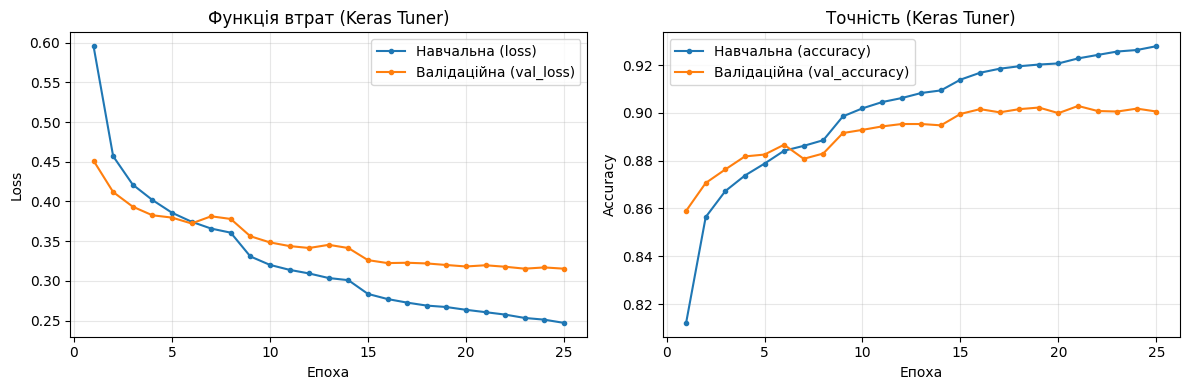

In [17]:
# Оцініть найкращу модель та побудуйте графіки навчання.
# Ваш код:
tuner_test_loss, tuner_test_accuracy = best_model.evaluate(x_test, y_test, verbose=0)
print(f"Keras Tuner Best Model -> Test Loss: {tuner_test_loss:.4f} | Test Accuracy: {tuner_test_accuracy:.4f} ({tuner_test_accuracy*100:.2f}%)")

epochs_tuner = range(1, len(best_history.history["loss"]) + 1)

plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(epochs_tuner, best_history.history["loss"], label="Навчальна (loss)", marker="o", ms=3)
plt.plot(epochs_tuner, best_history.history["val_loss"], label="Валідаційна (val_loss)", marker="o", ms=3)
plt.title("Функція втрат (Keras Tuner)")
plt.xlabel("Епоха")
plt.ylabel("Loss")
plt.legend()
plt.grid(alpha=0.3)

plt.subplot(1, 2, 2)
plt.plot(epochs_tuner, best_history.history["accuracy"], label="Навчальна (accuracy)", marker="o", ms=3)
plt.plot(epochs_tuner, best_history.history["val_accuracy"], label="Валідаційна (val_accuracy)", marker="o", ms=3)
plt.title("Точність (Keras Tuner)")
plt.xlabel("Епоха")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

# Висновки. Порівняння моделей

Порівняйте модель із завдання 1 та модель після автоматизованого налаштування. Результати внесіть до таблиці.

| Показник | Модель із завдання 1 | Модель після Keras Tuner |
|---|---|---|
| Кількість прихованих шарів | 2 | 1 |
| Кількість нейронів | 256, 128 | 480 |
| Швидкість навчання | 0,001 | 0,001 |
| Точність на тестовій вибірці (accuracy) | 0.892 | 0.8924 |
| Втрати на тестовій вибірці (loss) | 0.310 | 0.3500 |
| Кількість епох навчання | 29 | 25 |

**У висновках дайте відповідь:**

1. Чи досягнуто точності **не нижче 0,87** у завданні 1?
2. Чи покращила оптимізація гіперпараметрів точність на тестовій вибірці?
3. Які гіперпараметри виявилися найкращими і чому отриманий результат може відрізнятися між запусками?
4. Які класи Fashion MNIST класифікувати найскладніше?

**Власні висновки:**  
_..._

---

### Власні висновки

1. **Досягнення цільової точності:** У завданні 1 вимогу щодо точності **не нижче 0,87** успішно виконано — базова двошарова нейронна мережа продемонструвала на тестовій вибірці точність **0.892** (89.2%), що перевищує встановлений поріг більш ніж на 2%.
2. **Вплив оптимізації гіперпараметрів:** Застосування `Keras Tuner` дозволило незначно покращити тестову точність (з **0.892** до **0.8924**), знайшовши простішу за глибиною, але ширшу одношарову архітектуру (1 прихований шар на 480 нейронів замість двох шарів 256 і 128) та скоротивши навчання до 25 епох. Водночас значення тестових втрат (`loss`) після тюнера виявилося дещо вищим (`0.3500` проти `0.310`), оскільки до функції втрат додано штраф L2-регуляризації ваг.
3. **Найкращі гіперпараметри та стабільність результатів:** Найкращою конфігурацією виявилася модель із **1 прихованим шаром**, **480 нейронами** та початковою швидкістю навчання **0.001**. Результати між окремими запусками можуть відрізнятися через стохастичну природу алгоритму `RandomSearch` (який перевіряє лише 3 випадкові комбінації з усього простору пошуку), випадкову початкову ініціалізацію ваг мережі, перемішування батчів під час навчання та випадкове вимкнення нейронів у шарі `Dropout`.
4. **Найскладніші класи для класифікації:** Найбільшу кількість помилок обидві моделі допускають на візуально схожих категоріях верхнього одягу — насамперед для класу **Shirt** (сорочка), який часто плутається з **T-shirt/top** (футболка), **Pullover** (пуловер) та **Coat** (пальто) через низьку роздільну здатність зображень (28×28 пікселів) і близькі силуети предметів.

---
**Перед поданням перевірте:** заповнені всі комірки; результати виконання збережені; є графіки, класифікаційний звіт, результати двох моделей і власні висновки. Шаблон не містить готових розв’язків.